# Module 7: High-Frequency Trading: Order-Book Signals

**Business question:** Can ML use limit-order-book information to predict short-horizon price moves and improve execution? Does the prediction create **economic value after costs**?

**Chain:** order-book snapshot → P(UP / DOWN / NO_MOVE) → trading signal → backtest net of spread and fees → capital decision for the trading desk.

**What you will learn:** market microstructure (spread, order-book imbalance, microprice), target leakage, multi-class models, time-based splits, and turning probabilities into a trading rule.

## 0. Setup
In Colab, upload `nova_hft_orderbook.zip` to the data folder; the code reads the CSV straight from the zip.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, subprocess, importlib.util
if importlib.util.find_spec("google.colab"):             # Colab: install the extra libraries once
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap", "xgboost", "lightgbm", "imbalanced-learn"])
from pathlib import Path
import zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
try:
    from google.colab import drive; drive.mount("/content/drive")
except ImportError:
    pass
CANDIDATES = [Path("/content/drive/MyDrive/NovaFin_Capstone/data"), Path("../../Project"), Path("/mnt/project-files/Project")]
DATA = next(p for p in CANDIDATES if (p / "nova_hft_orderbook.zip").exists() or (p / "nova_hft_orderbook.csv").exists())
OUT = DATA.parent / "outputs" if "drive" in str(DATA) else Path("../outputs")
OUT.mkdir(exist_ok=True, parents=True)
SEED = 42
sns.set_theme(style="whitegrid", palette="deep")

## 1. Load and inspect
**Date format trap:** dates are written day-first (`05-01-2026` = 5 Jan 2026). Parsing them as month-first would scramble the day order and break the time split.

In [2]:
zp = DATA / "nova_hft_orderbook.zip"
if zp.exists():
    with zipfile.ZipFile(zp) as z:
        df = pd.read_csv(z.open("nova_hft_orderbook.csv"))
else:
    df = pd.read_csv(DATA / "nova_hft_orderbook.csv")
df["Timestamp"] = pd.to_datetime(df["Timestamp"], format="%d-%m-%Y %H:%M")
df["Trading_Day"] = pd.to_datetime(df["Trading_Day"], format="%d-%m-%Y")
df["Seq"] = np.arange(len(df))                        # file order is the only order within a minute
df["Target"] = df["Price_Move_Class"].replace({"FLAT": "NO_MOVE"})   # FLAT == brief's NO_MOVE
print(df.shape, "| stocks:", df.Stock.nunique(), "| days:", df.Trading_Day.nunique(), df.Trading_Day.min().date(), "to", df.Trading_Day.max().date())
df.Target.value_counts(normalize=True).round(3)

(120000, 35) | stocks: 10 | days: 20 2026-01-05 to 2026-01-30


Target
DOWN       0.419
UP         0.417
NO_MOVE    0.164
Name: proportion, dtype: float64

## 2. Microstructure EDA
Key concepts:
- **Spread** = ask − bid: the cost of trading immediately.
- **Order-book imbalance (OBI)** = (bid size − ask size) ÷ (bid size + ask size). More buyers queued than sellers tends to push the price up.
- **Microprice** = a size-weighted mid price; if it sits above the mid, the next move tends to be up.

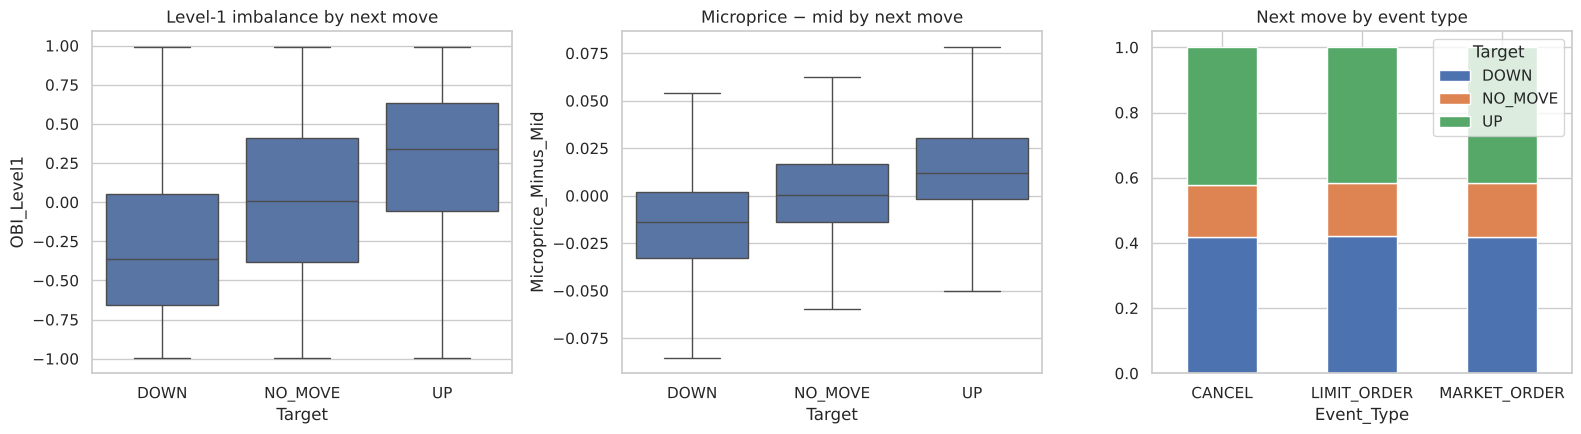

,OBI_Level1,OBI_3Level,Microprice_Minus_Mid,Relative_Spread,Order_Arrival_Rate,Cancellation_Rate
Target,,,,,,
DOWN,-0.26926,-0.21415,-0.01470,0.00014,44.67455,26.34825
NO_MOVE,0.01425,0.01101,0.00156,0.00013,43.28973,24.69224
UP,0.26126,0.20809,0.01403,0.00013,44.42634,25.37918


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=df, x="Target", y="OBI_Level1", order=["DOWN", "NO_MOVE", "UP"], ax=ax[0]).set_title("Level-1 imbalance by next move")
sns.boxplot(data=df, x="Target", y="Microprice_Minus_Mid", order=["DOWN", "NO_MOVE", "UP"], ax=ax[1], showfliers=False).set_title("Microprice − mid by next move")
pd.crosstab(df.Event_Type, df.Target, normalize="index").plot.bar(stacked=True, ax=ax[2], rot=0, title="Next move by event type")
plt.tight_layout(); plt.show()
df.groupby("Target")[["OBI_Level1", "OBI_3Level", "Microprice_Minus_Mid", "Relative_Spread", "Order_Arrival_Rate", "Cancellation_Rate"]].mean().round(5)

## 3. Remove leakage, build features
`Future_Return_100ms` and `Future_Price_100ms` **are the answer**: they are computed from the future. Using them as features would give near-perfect, fake accuracy. We drop them and the label. We also drop raw price levels, which identify the stock rather than the signal.

In [4]:
LEAKS = ["Future_Return_100ms", "Future_Price_100ms", "Price_Move_Class", "Target"]
X = df.drop(columns=LEAKS + ["Timestamp", "Trading_Day", "Stock", "Seq"])
X["Trade_Side"] = (X["Trade_Side"] == "BUY").astype(float)
X = pd.get_dummies(X, columns=["Event_Type"], dtype=float)
X = X.drop(columns=[c for c in X.columns if c.startswith(("Bid_Price", "Ask_Price"))] + ["Last_Price", "Mid_Price", "Microprice"])
X["Depth_Imbalance_3"] = (X[["Bid_Size_1", "Bid_Size_2", "Bid_Size_3"]].sum(axis=1) - X[["Ask_Size_1", "Ask_Size_2", "Ask_Size_3"]].sum(axis=1)) / X["Total_Depth"]
X["OBI_lag1"] = df.groupby("Stock")["OBI_Level1"].shift(1).fillna(0)
y = df["Target"]
print(X.shape); X.columns.tolist()

(120000, 22)


['Bid_Size_1',
 'Ask_Size_1',
 'Bid_Size_2',
 'Ask_Size_2',
 'Bid_Size_3',
 'Ask_Size_3',
 'Trade_Volume',
 'Trade_Side',
 'Order_Arrival_Rate',
 'Cancellation_Rate',
 'Short_Term_Volatility',
 'Spread',
 'Relative_Spread',
 'OBI_Level1',
 'OBI_3Level',
 'Total_Depth',
 'Microprice_Minus_Mid',
 'Event_Type_CANCEL',
 'Event_Type_LIMIT_ORDER',
 'Event_Type_MARKET_ORDER',
 'Depth_Imbalance_3',
 'OBI_lag1']

## 4. Split by trading day
20 trading days: first 14 **train**, next 3 **validation** (choose the trading threshold), last 3 **test** (report).

In [5]:
days = np.sort(df.Trading_Day.unique())
tr = df.Trading_Day.isin(days[:14]).values; va = df.Trading_Day.isin(days[14:17]).values; te = df.Trading_Day.isin(days[17:]).values
print("rows train/val/test:", tr.sum(), va.sum(), te.sum())

rows train/val/test: 84054 18070 17876


## 5. Direction models
Baseline: always predict the most common class (DOWN, 42%).

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, log_loss

models = {
    "Multinomial logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=50, random_state=SEED, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1, random_state=SEED, verbose=-1),
}
rows, proba = [], {}
base = y[tr].value_counts(normalize=True).idxmax()
rows.append(["Majority class", accuracy_score(y[te], [base] * te.sum()), f1_score(y[te], [base] * te.sum(), average="macro"), np.nan])
for name, m in models.items():
    m.fit(X[tr], y[tr])
    proba[name] = (m.predict_proba(X[va]), m.predict_proba(X[te]))
    pred = m.classes_[proba[name][1].argmax(1)]
    rows.append([name, accuracy_score(y[te], pred), f1_score(y[te], pred, average="macro"), log_loss(y[te], proba[name][1], labels=m.classes_)])
res = pd.DataFrame(rows, columns=["Model", "Accuracy", "Macro F1", "Log loss"]).set_index("Model").round(3)
res

,Accuracy,Macro F1,Log loss
Model,,,
Majority class,0.415,0.195,NaN
Multinomial logistic,0.605,0.440,0.907
Random forest,0.604,0.439,0.910
LightGBM,0.606,0.440,0.910


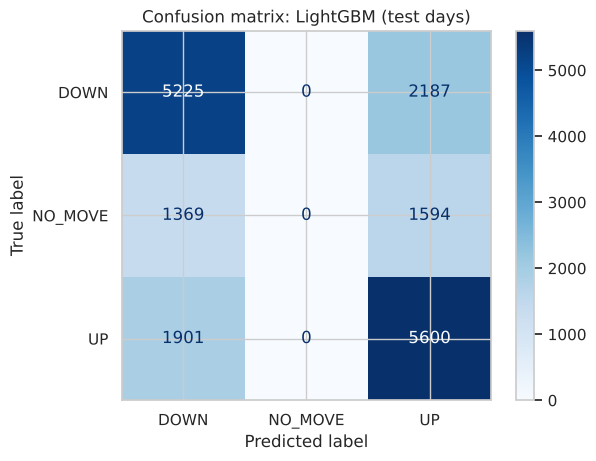

In [7]:
best = res["Accuracy"].drop("Majority class").idxmax()
classes = models[best].classes_
ConfusionMatrixDisplay(confusion_matrix(y[te], classes[proba[best][1].argmax(1)], labels=classes), display_labels=classes).plot(cmap="Blues")
plt.title(f"Confusion matrix: {best} (test days)"); plt.show()

**Reading it:** the model is far above the 42% baseline and gets UP vs DOWN mostly right; NO_MOVE is the hardest class (it is small and sits between the other two). Accuracy alone does not pay the bills, though: next we check money.

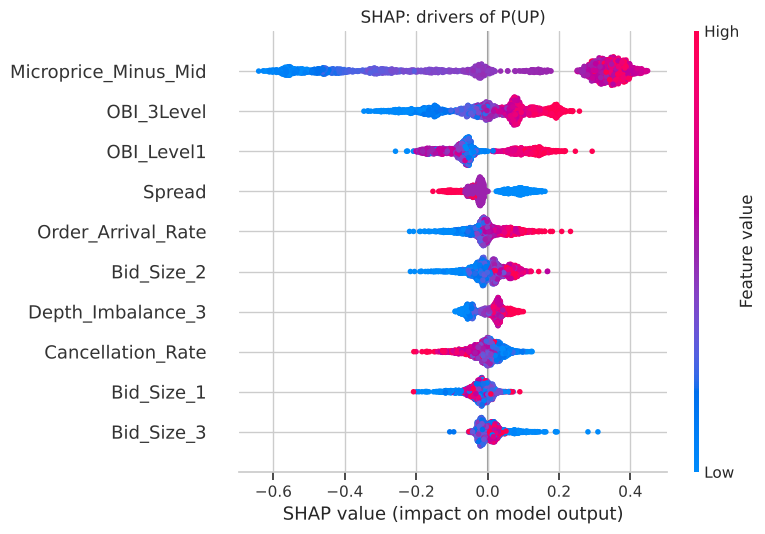

In [8]:
import shap
if best == "LightGBM":
    sample = X[te].sample(2000, random_state=SEED)
    sv = shap.TreeExplainer(models[best]).shap_values(sample)
    sv_up = sv[:, :, list(classes).index("UP")] if np.ndim(sv) == 3 else sv[list(classes).index("UP")]
    shap.summary_plot(sv_up, sample, max_display=10, show=False); plt.title("SHAP: drivers of P(UP)"); plt.tight_layout(); plt.show()
else:
    pd.Series(models[best].feature_importances_, X.columns).sort_values().tail(12).plot.barh(title="Feature importance"); plt.show()

## 6. From probabilities to a trading signal
**Rule:** buy if P(UP) > θ, sell if P(DOWN) > θ, otherwise do nothing. We hold for the 100 ms horizon.

**Costs:** crossing the spread to enter and exit costs one full relative spread per round trip, plus 0.5 bp exchange and clearing fees. We score trades with `Future_Return_100ms`, which is allowed here because it is the *outcome* of the trade, not an input.

θ is chosen on the **validation days**, then applied unchanged to the test days.

In [9]:
FEE = 0.00005
fut = df["Future_Return_100ms"].values; rel_spread = df["Relative_Spread"].values
iu, idn = list(classes).index("UP"), list(classes).index("DOWN")
def trade_pnl(P, mask, theta, cost_mult=1.0):
    up, dn = P[:, iu] > theta, P[:, idn] > theta
    side = np.where(up & ~dn, 1, np.where(dn & ~up, -1, 0))
    gross = side * fut[mask]
    net = gross - (side != 0) * (cost_mult * rel_spread[mask] + FEE)
    return side, gross, net
thetas = np.round(np.arange(0.40, 0.86, 0.05), 2)
val = pd.DataFrame([(t, *(lambda s, g, n: [(s != 0).sum(), n[s != 0].mean() * 1e4, n.sum() * 1e4])(*trade_pnl(proba[best][0], va, t))) for t in thetas],
                   columns=["theta", "trades", "avg net bps/trade", "total net bps"]).set_index("theta").round(2)
theta = val["total net bps"].idxmax()
print("Chosen threshold θ =", theta); val

Chosen threshold θ = 0.55


,trades,avg net bps/trade,total net bps
theta,,,
0.40,17635,0.78,13774.91
0.45,15776,1.03,16173.25
0.50,13734,1.29,17729.58
0.55,11790,1.58,18572.37
0.60,9723,1.86,18128.03
0.65,7287,2.20,16014.98
0.70,4682,2.56,11980.04
0.75,2415,2.96,7138.52
0.80,863,3.53,3043.60


In [10]:
side, gross, net = trade_pnl(proba[best][1], te, theta)
traded = side != 0
test_days = df.Trading_Day.values[te]
bt = pd.Series({
    "trades": traded.sum(), "trades per stock-day": traded.sum() / (df.Stock.nunique() * 3),
    "hit rate": (gross[traded] > 0).mean(),
    "avg gross bps/trade": gross[traded].mean() * 1e4, "avg cost bps/trade": (gross[traded] - net[traded]).mean() * 1e4,
    "avg net bps/trade": net[traded].mean() * 1e4,
    "net bps per day (sum over trades)": pd.Series(net * 1e4).groupby(test_days).sum().mean(),
}).round(3)
bt

trades                               11407.000
trades per stock-day                   380.233
hit rate                                 0.756
avg gross bps/trade                      3.568
avg cost bps/trade                       1.891
avg net bps/trade                        1.677
net bps per day (sum over trades)     6376.031
dtype: float64

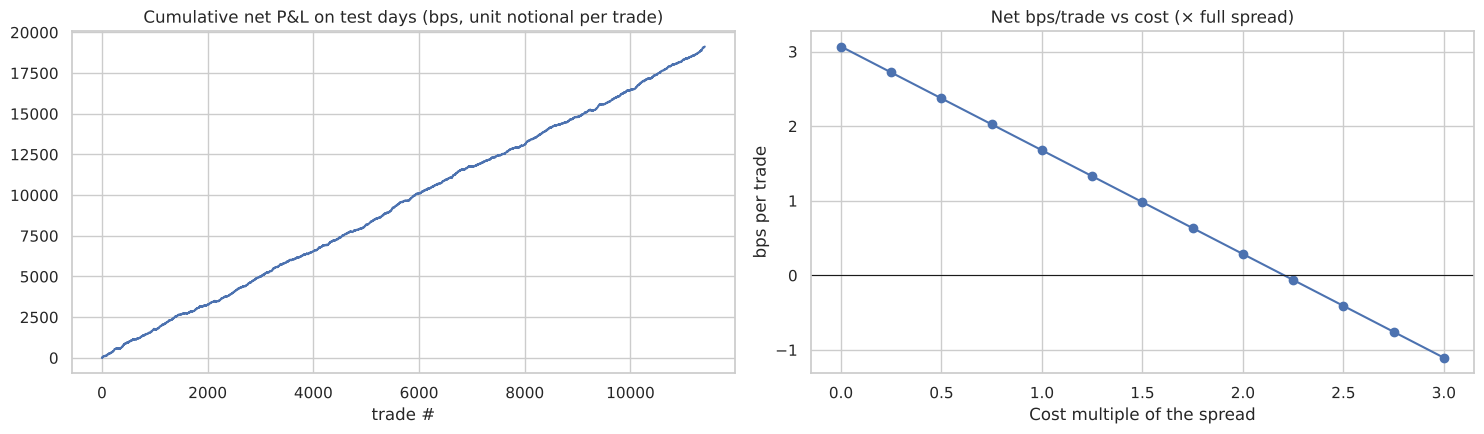

Edge disappears at about 2.25 × the spread


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(np.cumsum(net[traded]) * 1e4); ax[0].set(title="Cumulative net P&L on test days (bps, unit notional per trade)", xlabel="trade #")
mults = np.arange(0, 3.01, 0.25)
sens = [trade_pnl(proba[best][1], te, theta, k)[2][traded].mean() * 1e4 for k in mults]
ax[1].plot(mults, sens, marker="o"); ax[1].axhline(0, c="k", lw=0.8)
ax[1].set(title="Net bps/trade vs cost (× full spread)", xlabel="Cost multiple of the spread", ylabel="bps per trade")
plt.tight_layout(); plt.show()
breakeven = mults[np.argmax(np.array(sens) < 0)] if (np.array(sens) < 0).any() else ">3"
print("Edge disappears at about", breakeven, "× the spread")

## 7. Economic value and capacity
**Assumptions:** ₹10 lakh notional per trade; the desk can take 10% of the signals the model generates (queue position, market impact and risk limits stop it from taking them all). Daily P&L = trades × notional × net return.

In [12]:
NOTIONAL = 10e5; TAKE_UP = 0.10
daily_trades = traded.sum() / 3 * TAKE_UP
daily_pnl = daily_trades * NOTIONAL * net[traded].mean()
annual_pnl = daily_pnl * 250
print(f"Trades per day taken: {daily_trades:,.0f}")
print(f"Expected daily P&L: ₹{daily_pnl/1e5:,.2f} lakh | annual: ₹{annual_pnl/1e7:,.2f} crore")
print("Capital needed is mostly margin plus technology; the edge is capped by market capacity, not by capital.")

Trades per day taken: 380
Expected daily P&L: ₹0.64 lakh | annual: ₹1.59 crore
Capital needed is mostly margin plus technology; the edge is capped by market capacity, not by capital.


## 8. Save outputs

In [13]:
pd.Series({"model": best, "accuracy": res.loc[best, "Accuracy"], "baseline_accuracy": res.loc["Majority class", "Accuracy"], "theta": theta,
           "avg_net_bps": bt["avg net bps/trade"], "hit_rate": bt["hit rate"], "breakeven_cost_multiple": breakeven,
           "annual_pnl_inr": annual_pnl}).to_csv(OUT / "m7_hft_summary.csv")
print("Saved")

Saved


## 9. Conclusions
1. Order-book features carry a **real short-horizon signal**: accuracy is far above the 42% baseline, driven by order-flow features such as arrival and cancellation rates, volatility and imbalance.
2. After paying the full spread plus fees, the selective signal (high θ) still earns a positive net return per trade on unseen days.
3. The edge is **thin and cost-sensitive**: the sensitivity chart shows how fast it disappears as costs rise. Execution quality decides profitability.
4. **Recommendation:** a small, tightly limited allocation, used first to improve NovaFin's own order execution (timing large orders using the signal) and second as a capped market-making or prop book, with kill-switches and daily loss limits.
5. **Limits:** 20 days of synthetic data, minute-level timestamps, no market-impact or queue modelling, and the 10% take-up is an assumption.